<a href="https://colab.research.google.com/github/vzavala/StatsBook/blob/master/Python/ch6_sysid_co2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Additional example: data for system identification** (Victor M Zavala, UW-Madison, 2024).
A building of volume $V$ is ventilated with an air flow $q$; occupants generate CO$_2$ at a rate
$G$ per occupant. The indoor CO$_2$ concentration $x(t)$ responds to the input $u(t)$ as a first-order
system with gain $K=G/q$ and time constant $\tau=V/q$:
$$\tau\frac{dx}{dt}+x=K\,u(t),\qquad \textrm{transfer function } \frac{K}{\tau s+1}.$$
The input is zero at night and a sequence of hourly pulses of random height during the day.

| Symbol | Python | Meaning |
|---|---|---|
| $t$, $u(t)$, $x(t)$ | `t`, `u`, `x` | time [min], input [cfm], CO$_2$ concentration [ppm] |
| $G$, $V$, $q$ | `G`, `V`, `q` | CO$_2$ generation [ppm-cf/min], volume [cf], air flow [cfm] |
| $K$, $\tau$ | `K`, `tau` | gain and time constant [min] |

**Note:** This notebook creates the data of Example 6.15 (Section 6.3.3) of *Statistics for Chemical Engineers*: the CO2 response of a room to a rectangular input.

## Input signal

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lti, lsim

Fs = 1                    # sampling frequency [1/min]
T = 1 / Fs                # sampling period [min]
L = int(24 * 60 / T)      # length of the signal (one day)
t = np.arange(L) * T      # time [min]
np.random.seed(0)

Each hour is a pulse of 60 samples that is on for the first 50 minutes. The input is zero
for hours 1-8 and 18-24, and a pulse of random height in [50, 70] for hours 9-17.

In [2]:
stepdur = 50                                   # pulse duration [min]
t_pulse = np.arange(60) * T
u_pulse = (t_pulse < stepdur).astype(float)    # rectangular pulse
u = np.concatenate([0 * u_pulse] * 8
                   + [(50 + 20 * np.random.rand()) * u_pulse for _ in range(9)]
                   + [0 * u_pulse] * 7)

## Simulated response

Simulate the first-order system with the input $u(t)$, then add uniform noise in $[0,1]$ ppm and
the outdoor concentration (400 ppm).

K = 11.111,  tau = 10.10 min


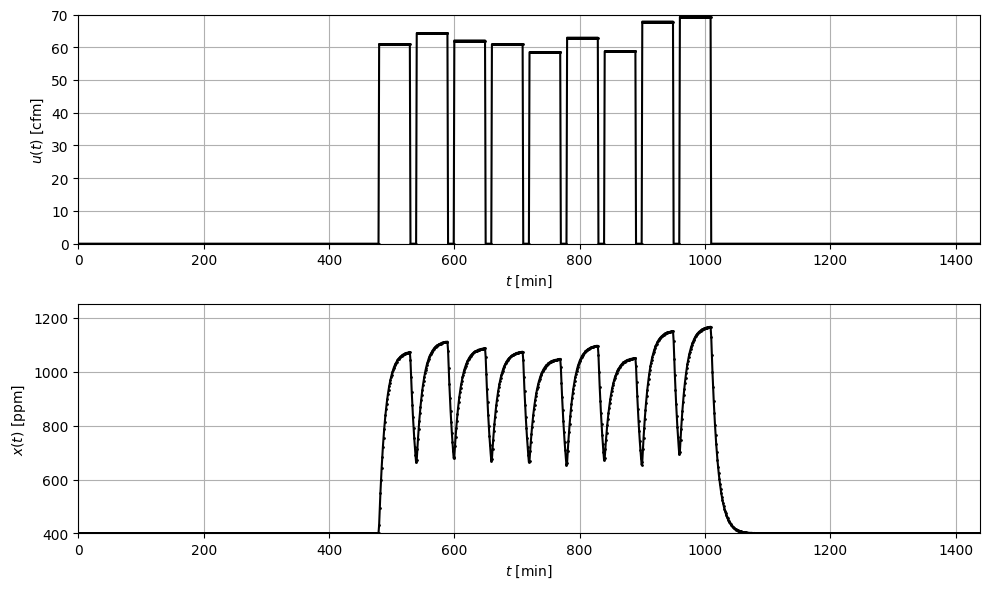

In [3]:
G = 1.1e4                 # ppm-cf/min (CO2 generation per occupant)
V = 10000                 # cf (building volume)
c_amb = 400               # ppm (fresh air CO2)
q = 15 * 66               # cfm (air flow)
K, tau = G / q, V / q
print(f"K = {K:.3f},  tau = {tau:.2f} min")

_, x, _ = lsim(lti([K], [tau, 1]), U=u, T=t)
x = x + np.random.rand(L) + c_amb

fig, axs = plt.subplots(2, 1, figsize=(10, 6))
axs[0].plot(t, u, 'k.-', markersize=2)
axs[0].set_ylabel(r'$u(t)$ [cfm]'); axs[0].set_xlim(0, t.max()); axs[0].set_ylim(0, 70)
axs[1].plot(t, x, 'k.-', markersize=2)
axs[1].set_ylabel(r'$x(t)$ [ppm]'); axs[1].set_xlim(0, t.max()); axs[1].set_ylim(400, 1250)
for ax in axs:
    ax.set_xlabel(r'$t$ [min]'); ax.grid(True)
plt.tight_layout()
plt.show()

The data set has three columns: $t$, $u(t)$, $x(t)$. The notebook `ch6_sysid_co2_est` reads the
stored file `Data/data_sysid_co2.dat` (created by the MATLAB script with the same settings; the
random pulse heights and noise differ between MATLAB and Python). To use this simulation instead,
save it with `np.savetxt('Data/data_sysid_co2.dat', data)`.

In [4]:
data = np.column_stack([t, u, x])
print(data.shape)

(1440, 3)


**Note:** The estimation itself is in the notebook ch6_sysid_co2_est.